In [1]:
import sys
import os
sys.path.insert(0, r"D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda")  # ưu tiên folder custom
import pandas as pd
import pickle
from sdv.single_table import MAECTGANSynthesizer
import numpy as np
import csv
import torch
# In kết quả
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,matthews_corrcoef
from sklearn.metrics import average_precision_score
from utils import plot_normal_vs_abnormal_tsne, plot_normal_vs_abnormal_pca,plot_normal_vs_abnormal_score_scatter
import pandas as pd
import sdv
print(sdv.__file__)

import ctgan
print(ctgan.__file__)

def load_threshold(path):
    with open(path, "rb") as f:
        return pickle.load(f)
    

D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda\sdv\__init__.py
D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda\ctgan\__init__.py


In [2]:
percentage = 1.0
dataset = "cic_ids"
epochs = 200
best_epoch = 20
margin = 5.0
lamda = 0.1



path_model=f"results/percentage_{percentage}/mae_{dataset}_{epochs}_margin_{margin}_lambda_{lamda}/checkpoints"
path_data=f"results/percentage_{percentage}/mae_{dataset}_{epochs}_margin_{margin}_lambda_{lamda}"
path_save_results=f"results/percentage_{percentage}/mae_{dataset}_{epochs}_margin_{margin}_lambda_{lamda}/per_attack_results/"
if not os.path.exists(path_save_results):
    os.makedirs(path_save_results)


X_test = pd.read_csv(f"{path_data}/{dataset}_X_test.csv")
y_test = pd.read_csv(f"{path_data}/{dataset}_y_test.csv")['label']
X_val_normal= pd.read_csv(f"{path_data}/{dataset}_X_val_normal.csv")
y_val_normal= pd.read_csv(f"{path_data}/{dataset}_y_val_normal.csv")['label']

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("X_val_normal shape:", X_val_normal.shape)
print("y_val_normal shape:", y_val_normal.shape)

model_file = f"{path_model}/MAE_{dataset}_epoch_{best_epoch}.pkl"
if not os.path.exists(model_file):
    print(f"Model file for epoch {best_epoch} does not exist: {model_file}")

synthesizer = MAECTGANSynthesizer.load(f'{path_model}/MAE_{dataset}_epoch_{best_epoch}.pkl')

avg_loss,threshold_re, threshold_z_0, threshold_95,threshold_99 = synthesizer.get_threshold_mae(X_val_normal)


print("Threshold_re:", threshold_re)
print("Threshold_z:", threshold_z_0)
print("Threshold_95:", threshold_95)
print("Threshold_99:", threshold_99)

X_test shape: (185897, 80)
y_test shape: (185897,)
X_val_normal shape: (43814, 80)
y_val_normal shape: (43814,)


c:\Users\Admin\anaconda3\envs\ctgan_env\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator BayesianGaussianMixture from version 1.8.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda\sdv\_utils.py:284: SDV Version Warning: You are currently on SDV version 1.32.0 but this synthesizer was created on version None. The latest bug fixes and features may not be available for this synthesizer. To see these enhancements, create and train a new synthesizer on this version.
  warnings.warn(message, SDVVersionWarning)


Threshold_re: (np.float32(0.017753003), np.float32(0.013654874))
Threshold_z: (np.float32(0.28616866), np.float32(0.42287445))
Threshold_95: 0.5913374
Threshold_99: 2.152898


In [3]:

def predict_and_evaluate(
    Z_norm_test,
    y_true,
    threshold,
    save_dir="results", 
    filename="test_results.csv",
    device="cuda" if torch.cuda.is_available() else "cpu",
    batch_size=128,
    k_std=3.0,
    mode="std" #"re" #"dist"    
):
    """
    AE-based anomaly detection evaluation
    - Predict anomaly using reconstruction error
    - Compute AUC, ACC, F1, Precision, Recall
    - Compute confusion matrix
    - Save everything to TXT
    """
    # -------------------------
    # Prediction
    # -------------------------
    os.makedirs(save_dir, exist_ok=True)
    save_path = os.path.join(save_dir, filename)
    print(f"Latent errors shape: {Z_norm_test.shape}")
    #y_true = np.concatenate(y_true)
    
    if mode=="re":
        mu, std = threshold
        threshold_test = mu + k_std * std
    elif mode=="std":
        mu, std = threshold
        threshold_test = mu + k_std * std
    elif mode=="dist":
        threshold_test = threshold
    
    y_pred = (Z_norm_test > threshold_test).astype(int)
    print("y_pred_shape:", y_pred.shape )
    
    print("Predicted label distribution in test set:")
    labels, counts = np.unique(y_pred, return_counts=True)
    for label, count in zip(labels, counts):
        print(f"Label {label}: {count} samples")
    
    
    
    y_true = (y_true != 0).astype(int)  # 0 = normal
    print("True label distribution in test set:")
    
    labels, counts = np.unique(y_true, return_counts=True)
    for label, count in zip(labels, counts):
        print(f"Label {label}: {count} samples")

    # =========================
    # 3. METRICS
    # =========================
    unique_classes = np.unique(y_true)

    # AUC-ROC
    if len(unique_classes) < 2:
        auc = 0.0
    else:
        auc = roc_auc_score(y_true, Z_norm_test)

    # PR-AUC (Average Precision)
    if len(unique_classes) < 2:
        pr_auc = 0.0
    else:
        pr_auc = average_precision_score(y_true, Z_norm_test)

    # Threshold-based metrics (fixed threshold => y_pred đã có)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)

    cm = confusion_matrix(y_true, y_pred)  # [[TN, FP],[FN, TP]]
    tn, fp, fn, tp = cm.ravel()

    # FAR = FP/(FP+TN)
    far = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    # MDR = FN/(FN+TP)
    mdr = fn / (fn + tp) if (fn + tp) > 0 else 0.0

    # MCC (fixed threshold)
    mcc = matthews_corrcoef(y_true, y_pred) if len(unique_classes) == 2 else 0.0
    
    results_df = pd.DataFrame({
    "Metric": [
        "Threshold",
        "AUC (ROC)",
        "PR-AUC",
        "FAR (FPR @ fixed thres)",
        "MDR (FNR @ fixed thres)",
        "ACC",
        "F1",
        "Precision",
        "Recall (TPR)",
        "MCC (fixed thres)"
    ],
    "Value": [
        threshold_test,
        auc,
        pr_auc,
        far,
        mdr,
        acc,
        f1,
        precision,
        recall,
        mcc
    ]
    })
    return results_df


In [4]:
#classify_test_data
print("Classify test data using MAE 95% error...")
test_re_loss, test_z_norm, test_y_true = synthesizer.get_score_mae(X_test, y_test)
results_df=predict_and_evaluate(
    Z_norm_test=test_z_norm,
    y_true=test_y_true,
    threshold=threshold_95,
    save_dir=path_save_results,
    filename=f"test_results_mae_95_epoch_{best_epoch}.csv",
    mode="dist"
)
display(results_df)
results_df.to_csv(
    f"{path_save_results}/test_results_mae_95_epoch_{best_epoch}.csv"
    )

Classify test data using MAE 95% error...
Latent errors shape: (185897,)
y_pred_shape: (185897,)
Predicted label distribution in test set:
Label 0: 143927 samples
Label 1: 41970 samples
True label distribution in test set:
Label 0: 153091 samples
Label 1: 32806 samples


,Metric,Value
0,Threshold,0.591337
1,AUC (ROC),0.934731
2,PR-AUC,0.880234
3,FAR (FPR @ fixed thres),0.092239
4,MDR (FNR @ fixed thres),0.151100
5,ACC,0.897373
6,F1,0.744865
7,Precision,0.663545
8,Recall (TPR),0.848900
9,MCC (fixed thres),0.689941


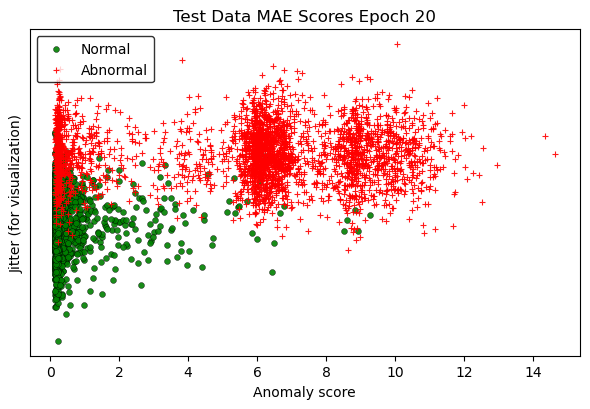

In [5]:
#tnse TEST DATA
plot_normal_vs_abnormal_score_scatter(
    test_z_norm[test_y_true==0],
    test_z_norm[test_y_true!=0],
    title=f"Test Data MAE Scores Epoch {best_epoch}",
    save_path=f"{path_save_results}/score_scatter_plot_test_data.png",
    labels=["Normal","Abnormal"]
)
    
    


##1. Xử lý với Bot attack



===========================Processing attack: Bot===========================
Classify test attack: Bot using MAE 95% error...
Latent errors shape: (153229,)
y_pred_shape: (153229,)
Predicted label distribution in test set:
Label 0: 139128 samples
Label 1: 14101 samples
True label distribution in test set:
Label 0: 153091 samples
Label 1: 138 samples


,Metric,Value
0,Threshold,0.591337
1,AUC (ROC),0.793062
2,PR-AUC,0.004726
3,FAR (FPR @ fixed thres),0.091619
4,MDR (FNR @ fixed thres),0.456522
5,ACC,0.908053
6,F1,0.010534
7,Precision,0.005319
8,Recall (TPR),0.543478
9,MCC (fixed thres),0.046891


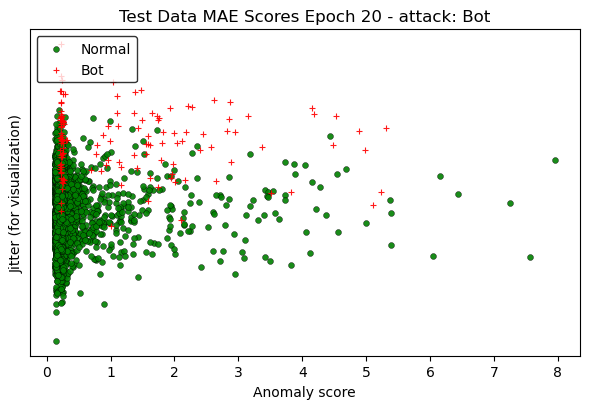



===========================Processing attack: DoS_slowloris===========================
Classify test attack: DoS_slowloris using MAE 95% error...
Latent errors shape: (153497,)
y_pred_shape: (153497,)
Predicted label distribution in test set:
Label 0: 139244 samples
Label 1: 14253 samples
True label distribution in test set:
Label 0: 153091 samples
Label 1: 406 samples


,Metric,Value
0,Threshold,0.591337
1,AUC (ROC),0.914730
2,PR-AUC,0.149554
3,FAR (FPR @ fixed thres),0.091619
4,MDR (FNR @ fixed thres),0.440887
5,ACC,0.907457
6,F1,0.030971
7,Precision,0.015926
8,Recall (TPR),0.559113
9,MCC (fixed thres),0.082732


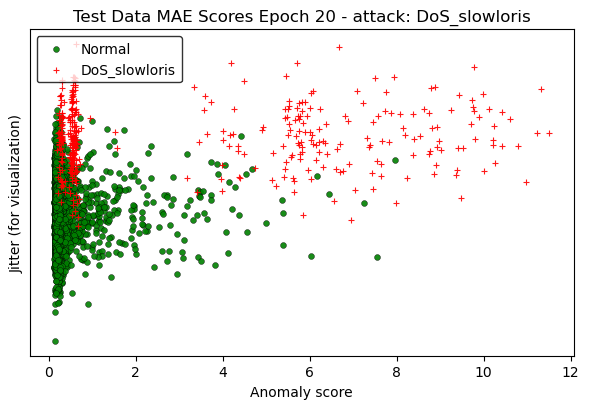



===========================Processing attack: DoS_Slowhttptest===========================
Classify test attack: DoS_Slowhttptest using MAE 95% error...
Latent errors shape: (153476,)
y_pred_shape: (153476,)
Predicted label distribution in test set:
Label 0: 139330 samples
Label 1: 14146 samples
True label distribution in test set:
Label 0: 153091 samples
Label 1: 385 samples


,Metric,Value
0,Threshold,0.591337
1,AUC (ROC),0.801096
2,PR-AUC,0.244157
3,FAR (FPR @ fixed thres),0.091619
4,MDR (FNR @ fixed thres),0.688312
5,ACC,0.906884
6,F1,0.016516
7,Precision,0.008483
8,Recall (TPR),0.311688
9,MCC (fixed thres),0.038056


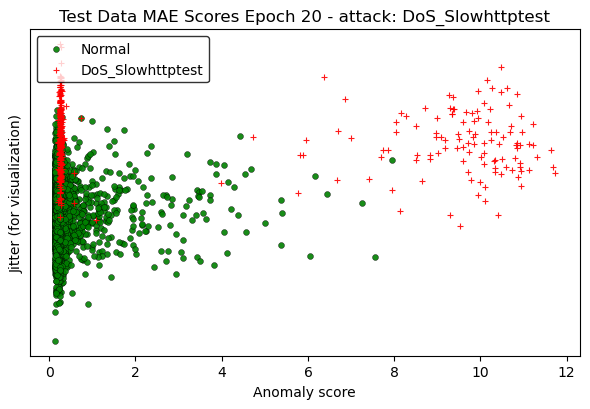



===========================Processing attack: FTP-Patator===========================
Classify test attack: FTP-Patator using MAE 95% error...
Latent errors shape: (153647,)
y_pred_shape: (153647,)
Predicted label distribution in test set:
Label 0: 139066 samples
Label 1: 14581 samples
True label distribution in test set:
Label 0: 153091 samples
Label 1: 556 samples


,Metric,Value
0,Threshold,0.591337
1,AUC (ROC),0.995547
2,PR-AUC,0.533196
3,FAR (FPR @ fixed thres),0.091619
4,MDR (FNR @ fixed thres),0.001799
5,ACC,0.908706
6,F1,0.073330
7,Precision,0.038063
8,Recall (TPR),0.998201
9,MCC (fixed thres),0.185744


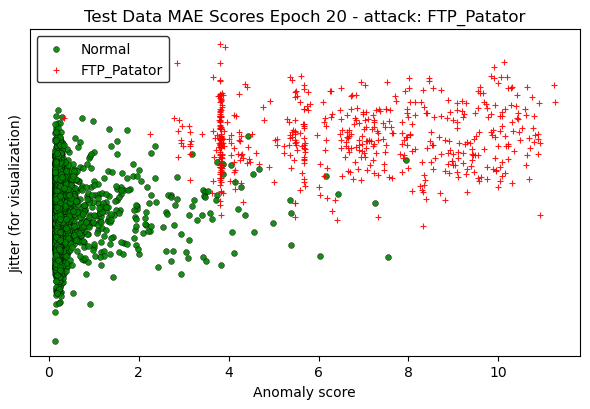



===========================Processing attack: SSH-Patator===========================
Classify test attack: SSH-Patator using MAE 95% error...
Latent errors shape: (153504,)
y_pred_shape: (153504,)
Predicted label distribution in test set:
Label 0: 139289 samples
Label 1: 14215 samples
True label distribution in test set:
Label 0: 153091 samples
Label 1: 413 samples


,Metric,Value
0,Threshold,0.591337
1,AUC (ROC),0.838256
2,PR-AUC,0.020285
3,FAR (FPR @ fixed thres),0.091619
4,MDR (FNR @ fixed thres),0.542373
5,ACC,0.907169
6,F1,0.025841
7,Precision,0.013296
8,Recall (TPR),0.457627
9,MCC (fixed thres),0.065405


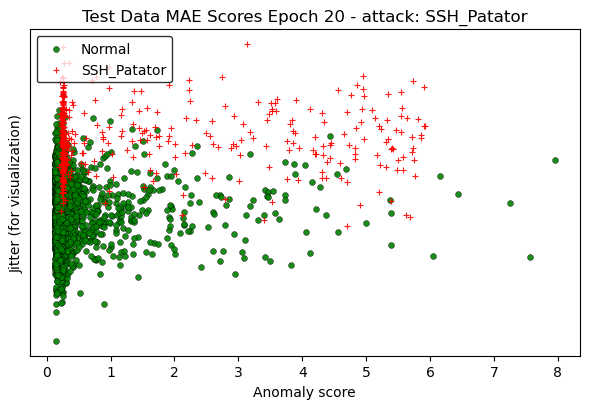



===========================Processing attack: DoS_GoldenEye===========================
Classify test attack: DoS_GoldenEye using MAE 95% error...
Latent errors shape: (153811,)
y_pred_shape: (153811,)
Predicted label distribution in test set:
Label 0: 139190 samples
Label 1: 14621 samples
True label distribution in test set:
Label 0: 153091 samples
Label 1: 720 samples


,Metric,Value
0,Threshold,0.591337
1,AUC (ROC),0.921247
2,PR-AUC,0.351882
3,FAR (FPR @ fixed thres),0.091619
4,MDR (FNR @ fixed thres),0.173611
5,ACC,0.907997
6,F1,0.077570
7,Precision,0.040695
8,Recall (TPR),0.826389
9,MCC (fixed thres),0.171002


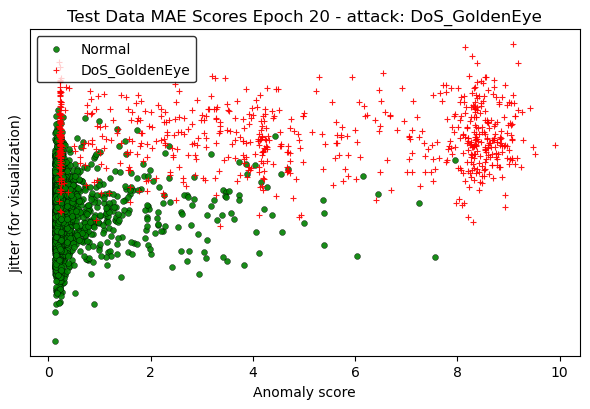



===========================Processing attack: DoS_Hulk===========================
Classify test attack: DoS_Hulk using MAE 95% error...
Latent errors shape: (169228,)
y_pred_shape: (169228,)
Predicted label distribution in test set:
Label 0: 140264 samples
Label 1: 28964 samples
True label distribution in test set:
Label 0: 153091 samples
Label 1: 16137 samples


,Metric,Value
0,Threshold,0.591337
1,AUC (ROC),0.981005
2,PR-AUC,0.899313
3,FAR (FPR @ fixed thres),0.091619
4,MDR (FNR @ fixed thres),0.074301
5,ACC,0.910033
6,F1,0.662424
7,Precision,0.515744
8,Recall (TPR),0.925699
9,MCC (fixed thres),0.650417


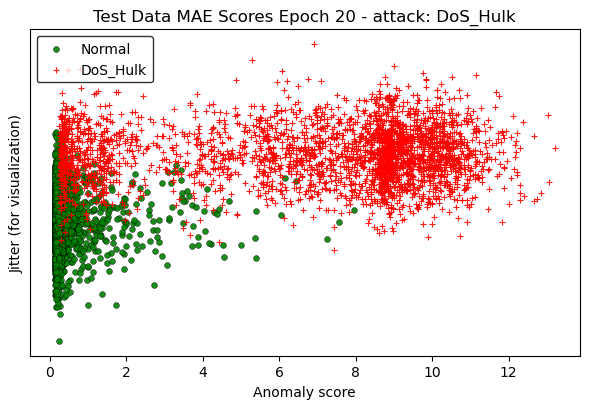



===========================Processing attack: DDoS===========================
Classify test attack: DDoS using MAE 95% error...
Latent errors shape: (156019,)
y_pred_shape: (156019,)
Predicted label distribution in test set:
Label 0: 141937 samples
Label 1: 14082 samples
True label distribution in test set:
Label 0: 153091 samples
Label 1: 2928 samples


,Metric,Value
0,Threshold,0.591337
1,AUC (ROC),0.466934
2,PR-AUC,0.015775
3,FAR (FPR @ fixed thres),0.091619
4,MDR (FNR @ fixed thres),0.980874
5,ACC,0.891693
6,F1,0.006584
7,Precision,0.003977
8,Recall (TPR),0.019126
9,MCC (fixed thres),-0.034330


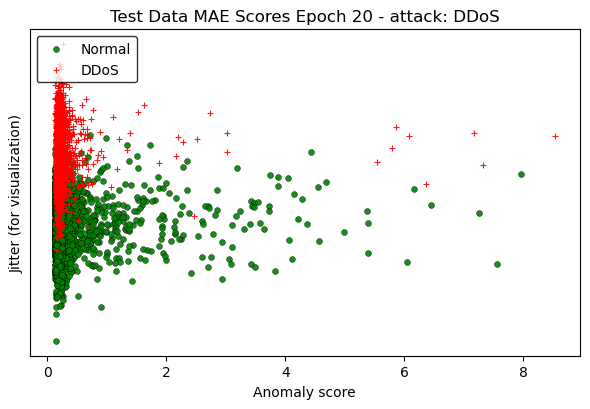



===========================Processing attack: PortScan===========================
Classify test attack: PortScan using MAE 95% error...
Latent errors shape: (164211,)
y_pred_shape: (164211,)
Predicted label distribution in test set:
Label 0: 139065 samples
Label 1: 25146 samples
True label distribution in test set:
Label 0: 153091 samples
Label 1: 11120 samples


,Metric,Value
0,Threshold,0.591337
1,AUC (ROC),0.997785
2,PR-AUC,0.910155
3,FAR (FPR @ fixed thres),0.091619
4,MDR (FNR @ fixed thres),0.000000
5,ACC,0.914586
6,F1,0.613247
7,Precision,0.442217
8,Recall (TPR),1.000000
9,MCC (fixed thres),0.633800


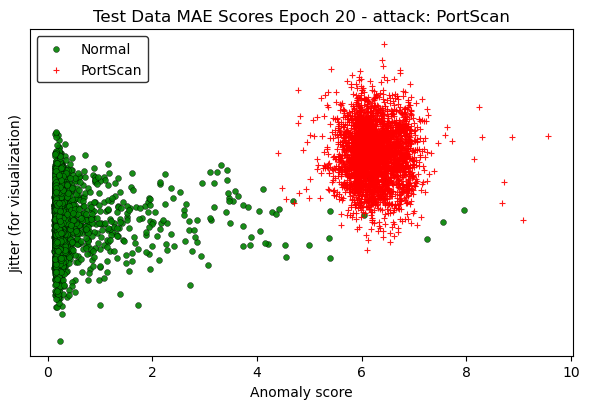

In [6]:
attack_list=["Bot","DoS_slowloris","DoS_Slowhttptest","FTP-Patator","SSH-Patator","DoS_GoldenEye","DoS_Hulk","DDoS","PortScan"]

for attack_name in attack_list:
    print(f"\n\n===========================Processing attack: {attack_name}===========================")
    path_attack= f"data/cic-ids/per_attack_test/{attack_name}.csv"
    X_attack= pd.read_csv(path_attack)
    y_attack = np.ones(len(X_attack), dtype=int)  # all abnormal = 1
    x_test_normal=X_test[y_test==0].reset_index(drop=True)
    y_test_normal=y_test[y_test==0].reset_index(drop=True)

    X_combined = pd.concat([x_test_normal, X_attack], ignore_index=True)
    y_combined = np.concatenate([y_test_normal, y_attack])


    #classify_test_data
    print(f"Classify test attack: {attack_name} using MAE 95% error...")
    test_re_loss, test_z_norm, test_y_true = synthesizer.get_score_mae(X_combined, y_combined)
    results_df=predict_and_evaluate(
        Z_norm_test=test_z_norm,
        y_true=y_combined,
        threshold=threshold_95,
        save_dir=path_data,
        filename=f"test_results_mae_95_epoch_{best_epoch}_{attack_name}.csv",
        mode="dist"
    )
    #tnse TEST DATA
    display(results_df)
    attack_name_split=attack_name.replace("-","_").replace(" ","_")
    plot_normal_vs_abnormal_score_scatter(
        test_z_norm[y_combined==0],
        test_z_norm[y_combined!=0],
        title=f"Test Data MAE Scores Epoch {best_epoch} - attack: {attack_name_split}",
        save_path=f"{path_save_results}/score_scatter_plot_{attack_name}.png",
        labels=["Normal",attack_name_split]
    )
        

    

